## 3. Plot cell-type marker genes on our UMAP, and by leiden cluster

#### Import libraries

In [ ]:
import os, sys
import scanpy as sc

import pandas as pd
import numpy as np
from pathlib import Path
_p = Path(".").resolve()
while not (_p / "src" / "config.py").exists() and _p != _p.parent:
    _p = _p.parent
sys.path.insert(0, str(_p))
from src.config import ANALYSIS_DIR, FIGURES_DIR


In [2]:
os.getcwd()

'/Users/stanleydale/user_generated/breault-lab/single-cell/notebooks/D2_DZ'

In [ ]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path("../..").resolve()))
from src.markers import cell_type_markers

In [4]:
## include a scanpy save directory for the figures

In [5]:
os.getcwd()

'/Users/stanleydale/user_generated/breault-lab/single-cell/analysis'

In [7]:
d2_dz = sc.read_h5ad(ANALYSIS_DIR / "data-objects/clustered/clustered_egfDuod_D2_DZ.h5ad")

In [8]:
d2_dz

AnnData object with n_obs × n_vars = 46210 × 27844
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'freemuxlet.identity', 'participant', 'Condition', 'Time_point', 'Treatment', 'ident', 'leiden'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'X_name', 'hvg'
    obsm: 'X_pca', 'X_umap'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [9]:
d2_dz.n_vars
d2_dz.var_names[:5]
'LGR5' in d2_dz.var_names, 'AXIN2' in d2_dz.var_names, 'ASCL2' in d2_dz.var_names


(True, True, True)

In [10]:
print(d2_dz.obs['orig.ident'].unique())

['D2']
Categories (1, object): ['D2']


In [11]:
print(d2_dz.obs['leiden'].unique())

['11', '2', '4', '5', '0', ..., '21', '12', '20', '16', '23']
Length: 24
Categories (24, object): ['0', '1', '2', '3', ..., '20', '21', '22', '23']


In [12]:
ISC_markers = cell_type_markers['ISCs']    
PC_markers = cell_type_markers['PCs'] 
Proliferating_PC_markers = cell_type_markers['Proliferating PCs']
Enterocyte_markers = cell_type_markers['Enterocytes']
Goblet_markers = cell_type_markers['Goblet cells']
EEC_markers = cell_type_markers['EECs']


In [ ]:
d2_dz

AnnData object with n_obs × n_vars = 46210 × 27844
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'freemuxlet.identity', 'participant', 'Condition', 'Time_point', 'Treatment', 'ident', 'leiden', 'ISC_score'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'X_name', 'hvg'
    obsm: 'X_pca', 'X_umap'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [ ]:
sc.tl.score_genes(d2_dz, gene_list = PC_markers, score_name='PC_score')

In [ ]:
'NEUROG3' in d2_dz.var.index

False

In [ ]:
d2_dz

AnnData object with n_obs × n_vars = 46210 × 27844
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'freemuxlet.identity', 'participant', 'Condition', 'Time_point', 'Treatment', 'ident', 'leiden', 'ISC_score', 'PC_score', 'Enterocyte score'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'X_name', 'hvg'
    obsm: 'X_pca', 'X_umap'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

## Now we move to plotting heatmap panels for each set of marker genes across the entire umap

#### ISCs

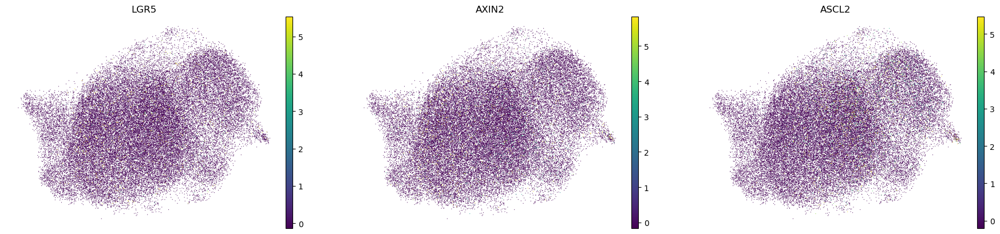

In [14]:
## I think these proportions are slightly confusing. It might be because we don't have all of the markers represented in the scoring

present = [g for g in ISC_markers
           if (hasattr(d2_dz, "raw") and d2_dz.raw is not None and g in d2_dz.raw.var_names) or
              (g in d2_dz.var_names)]

sc.pl.umap(
    d2_dz,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    vmax="p99",            # nicer dynamic range
    frameon=False
)

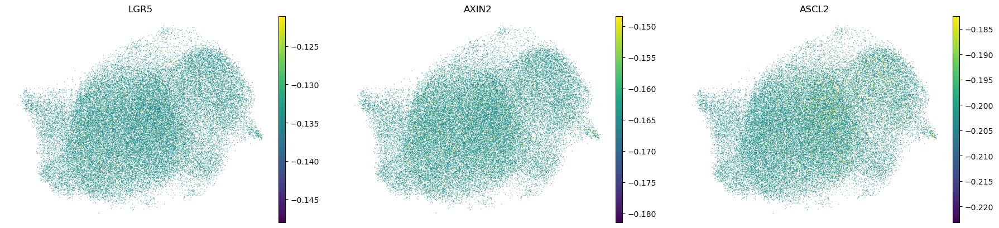

In [15]:
## Let's try and increase the dynamic range by squashing the scale

present = [g for g in ISC_markers
           if (hasattr(d2_dz, "raw") and d2_dz.raw is not None and g in d2_dz.raw.var_names) or
              (g in d2_dz.var_names)]

sc.pl.umap(
    d2_dz,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    vmax="p95",            # nicer dynamic range
    frameon=False
)

### Let's try a new set of ISC markers

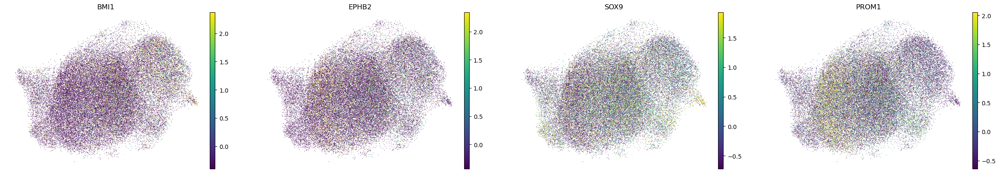

In [26]:
More_Isc_markers = ["BMI1", "EPHB2", "SOX9", "PROM1"]

## I think these proportions are slightly confusing. It might be because we don't have all of the markers represented in the scoring

present = [g for g in More_Isc_markers
           if (hasattr(d2_dz, "raw") and d2_dz.raw is not None and g in d2_dz.raw.var_names) or
              (g in d2_dz.var_names)]

sc.pl.umap(
    d2_dz,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    vmax="p95",            # nicer dynamic range
    frameon=False
)

#### PCs

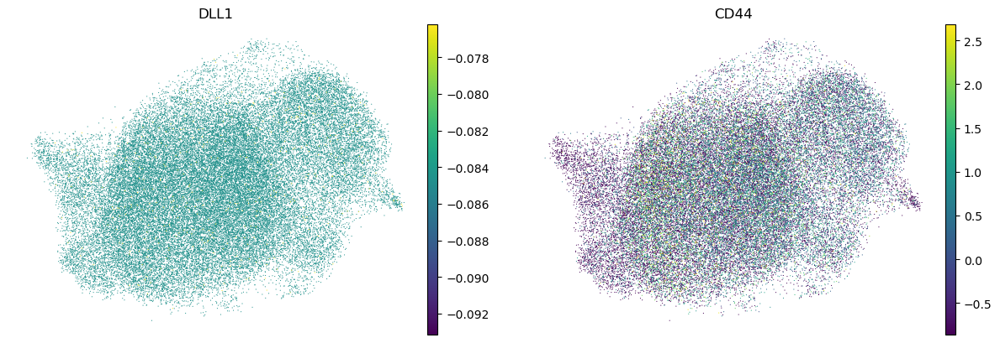

In [16]:
present = [g for g in PC_markers
           if (hasattr(d2_dz, "raw") and d2_dz.raw is not None and g in d2_dz.raw.var_names) or
              (g in d2_dz.var_names)]

sc.pl.umap(
    d2_dz,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    vmax="p99",            # nicer dynamic range
    frameon=False
)

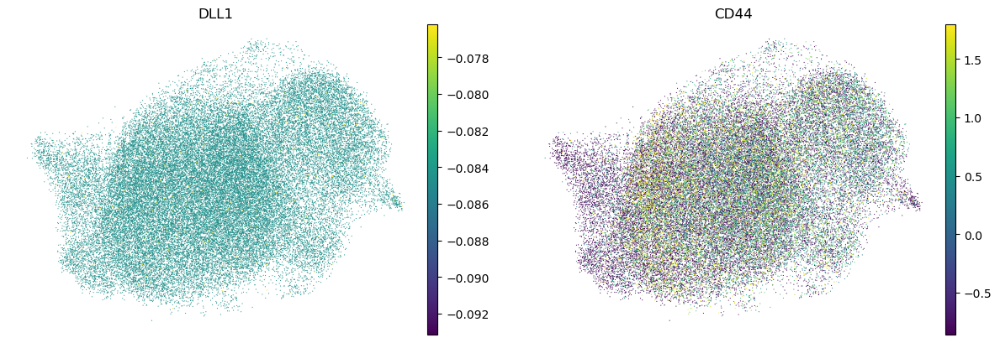

In [17]:
## Again I want to increase the dynamic range: 

present = [g for g in PC_markers
           if (hasattr(d2_dz, "raw") and d2_dz.raw is not None and g in d2_dz.raw.var_names) or
              (g in d2_dz.var_names)]

sc.pl.umap(
    d2_dz,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    vmax="p95",            # nicer dynamic range
    frameon=False
)

In [18]:
d2_dz

AnnData object with n_obs × n_vars = 46210 × 27844
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'freemuxlet.identity', 'participant', 'Condition', 'Time_point', 'Treatment', 'ident', 'leiden'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'X_name', 'hvg'
    obsm: 'X_pca', 'X_umap'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

#### Proliferating PCs

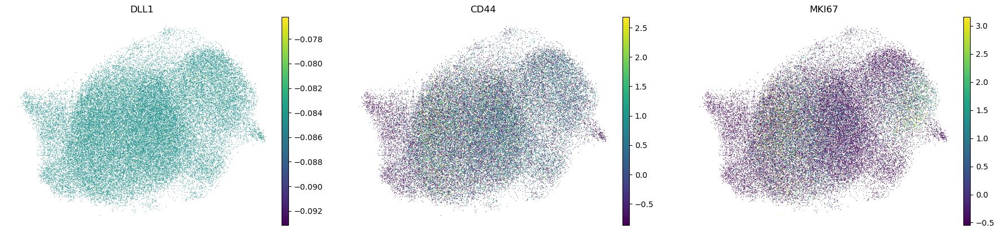

In [19]:
present = [g for g in Proliferating_PC_markers
           if (hasattr(d2_dz, "raw") and d2_dz.raw is not None and g in d2_dz.raw.var_names) or
              (g in d2_dz.var_names)]

sc.pl.umap(
    d2_dz,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    vmax="p99",            # nicer dynamic range
    frameon=False
)

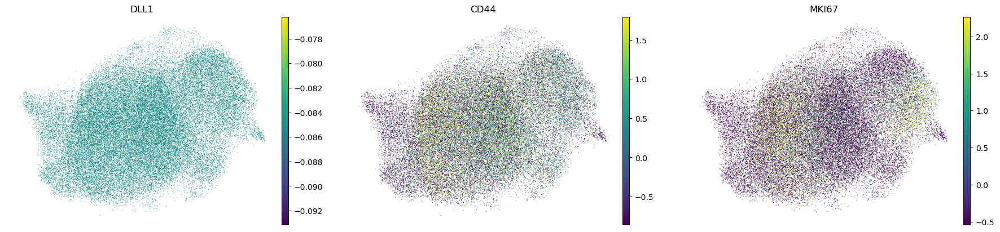

In [20]:
present = [g for g in Proliferating_PC_markers
           if (hasattr(d2_dz, "raw") and d2_dz.raw is not None and g in d2_dz.raw.var_names) or
              (g in d2_dz.var_names)]

sc.pl.umap(
    d2_dz,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    vmax="p95",            # nicer dynamic range
    frameon=False
)

### Let's plot ATOH1, a progenitor cell marker



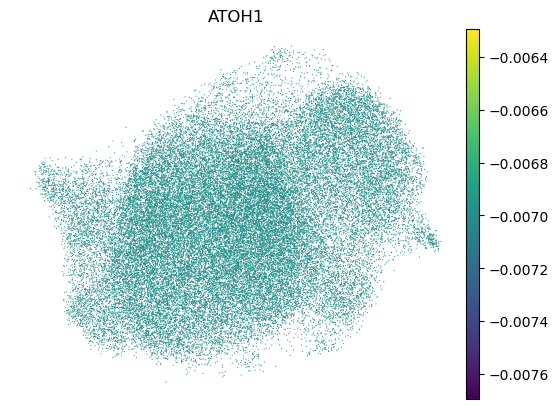

In [27]:
More_Isc_markers = ["ATOH1"]

## I think these proportions are slightly confusing. It might be because we don't have all of the markers represented in the scoring

present = [g for g in More_Isc_markers
           if (hasattr(d2_dz, "raw") and d2_dz.raw is not None and g in d2_dz.raw.var_names) or
              (g in d2_dz.var_names)]

sc.pl.umap(
    d2_dz,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    vmax="p95",            # nicer dynamic range
    frameon=False
)

#### Secretory PC markers


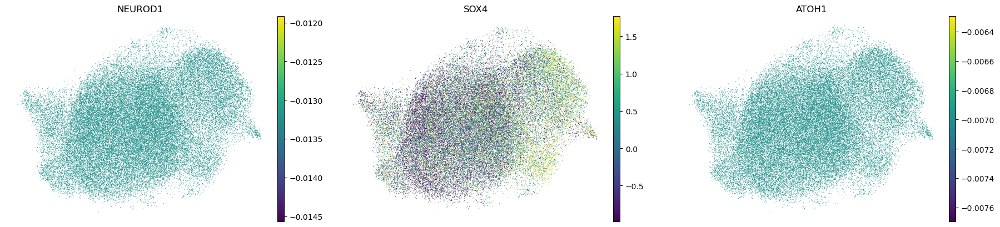

In [28]:
Secretory_PC_markers = ["NEUROG3", "INSM1", "NEUROD1", "SOX4", "ATOH1"]


present = [g for g in Secretory_PC_markers
           if (hasattr(d2_dz, "raw") and d2_dz.raw is not None and g in d2_dz.raw.var_names) or
              (g in d2_dz.var_names)]

sc.pl.umap(
    d2_dz,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    vmax="p95",            # nicer dynamic range
    frameon=False
)


### Inflammed secretory markers

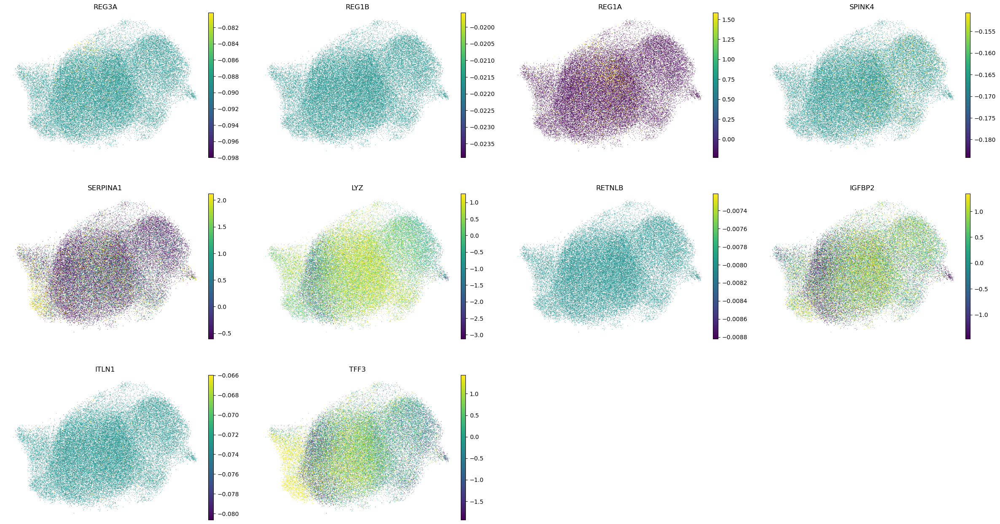

In [31]:
### Let's try plotting our inflammatory secretory markers

Inflammed_Secretory_PC_markers = ["REG3A",
"DEFA6",
"REG1B",
"REG1A",
"SPINK4",
"SERPINA1",
"LYZ",
"RETNLB",
"IGFBP2",
"ITLN1",
"TFF3"]


present = [g for g in Inflammed_Secretory_PC_markers
           if (hasattr(d2_dz, "raw") and d2_dz.raw is not None and g in d2_dz.raw.var_names) or
              (g in d2_dz.var_names)]

sc.pl.umap(
    d2_dz,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    vmax="p95",            # nicer dynamic range
    frameon=False
)

### Plot the markers by cluster

#### Enterocytes

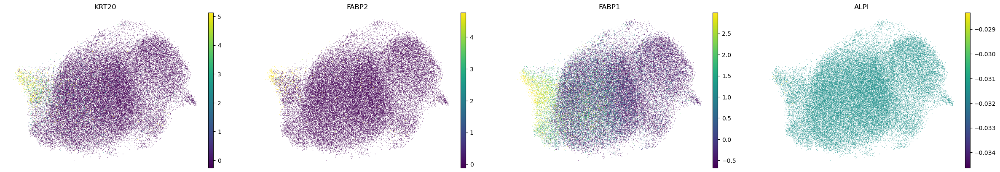

In [21]:
present = [g for g in Enterocyte_markers
           if (hasattr(d2_dz, "raw") and d2_dz.raw is not None and g in d2_dz.raw.var_names) or
              (g in d2_dz.var_names)]

sc.pl.umap(
    d2_dz,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    vmax="p99",            # nicer dynamic range
    frameon=False
)

#### Goblet cells

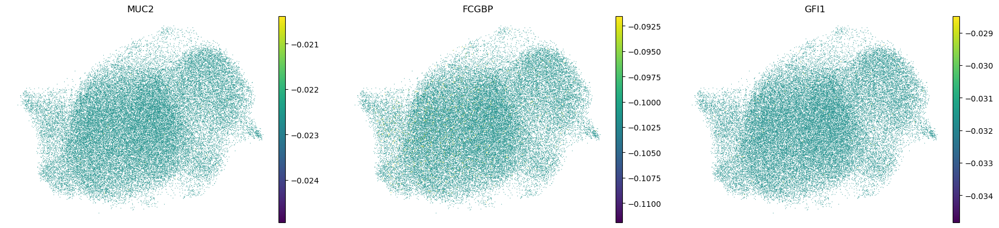

In [22]:
present = [g for g in Goblet_markers
           if (hasattr(d2_dz, "raw") and d2_dz.raw is not None and g in d2_dz.raw.var_names) or
              (g in d2_dz.var_names)]

sc.pl.umap(
    d2_dz,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    vmax="p95",            # nicer dynamic range
    frameon=False
)

#### EECs

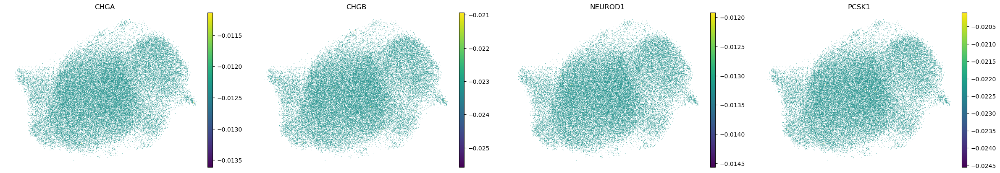

In [23]:
present = [g for g in EEC_markers
           if (hasattr(d2_dz, "raw") and d2_dz.raw is not None and g in d2_dz.raw.var_names) or
              (g in d2_dz.var_names)]

sc.pl.umap(
    d2_dz,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    vmax="p99",            # nicer dynamic range
    frameon=False
)

### Absolute expression heatmaps, for all markers

In [ ]:


adata = d2_dz  # <-- or your AnnData
cluster_key = "leiden"         # change if you used a different key

# Example markers dict:
# markers = {"Stem/ISC": ["LGR5", "ASCL2"], "Enterocyte": ["ALPI","APOA1"], ...}
# (Use your own dict here)
markers = cell_type_markers

# — ensure leiden is categorical & optional dendrogram ordering —
adata.obs[cluster_key] = adata.obs[cluster_key].astype("category")
sc.tl.dendrogram(adata, groupby=cluster_key)  # enables consistent ordering across plots

# — keep only genes present in adata.var_names (case-sensitive) —
varset = set(adata.var_names)
filtered_markers = {k: [g for g in v if g in varset] for k, v in markers.items()}
missing = {k: sorted(set(v) - varset) for k, v in markers.items() if any(g not in varset for g in v)}

# (optional) quick notice in notebook:
print("Missing genes (ignored):")
for k, lst in missing.items():
    if lst: print(f"  {k}: {', '.join(lst)}")

# If you prefer uppercase matching, uncomment this mapping:
# name_map = {g.upper(): g for g in adata.var_names}
# filtered_markers = {k: [name_map[g] for g in v if g.upper() in name_map] for k,v in markers.items()}

Missing genes (ignored):
  PCs: NEUROG3
  Proliferating PCs: NEUROG3
  Secretory PCs: INSM1, NEUROG3
  EECs: NEUROG3, PAX4


[<Axes: title={'center': 'LGR5'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'AXIN2'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'ASCL2'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'DLL1'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'CD44'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'MKI67'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'NEUROD1'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'SOX4'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'ATOH1'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'KRT20'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'FABP2'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'FABP1'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'ALPI'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'MUC2'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'FCGBP'}, xlabel='UMAP1', y

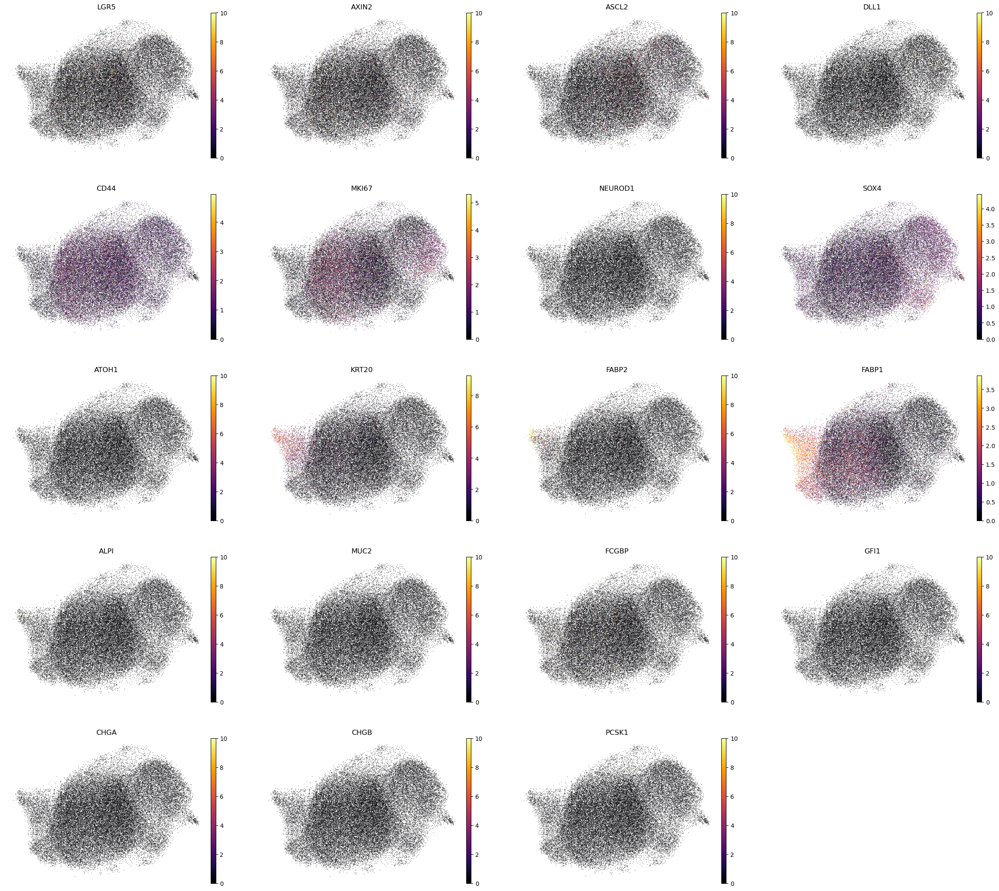

In [25]:

# Flatten your markers dict into a unique list
all_markers = []
for genes in filtered_markers.values():
    all_markers.extend(genes)
all_markers = list(dict.fromkeys(all_markers))  # preserve order, remove dups

sc.settings.figdir = str(FIGURES_DIR / "marker-genes/d2-dz")

sc.pl.umap(
    adata,
    color=all_markers,         # list of genes
    vmin=0, vmax=None,         # adjust if needed
    ncols=4,
    cmap="inferno",
    frameon=False,
    show=False
)
sc.pl.umap(
    adata,
    color=all_markers,
    ncols=4,
    cmap="inferno",
    frameon=False,
    show=False,
    save="_d2_dz_umap_marker_genes.pdf"
)


categories: 0, 1, 2, etc.
var_group_labels: ISCs, PCs, Proliferating PCs, etc.
categories: 0, 1, 2, etc.
var_group_labels: ISCs, PCs, Proliferating PCs, etc.


{'mainplot_ax': <Axes: >,
 'group_extra_ax': <Axes: >,
 'gene_group_ax': <Axes: >,
 'size_legend_ax': <Axes: title={'center': 'Fraction of cells\nin group (%)'}>,
 'color_legend_ax': <Axes: title={'center': 'Mean expression\nin group'}>}

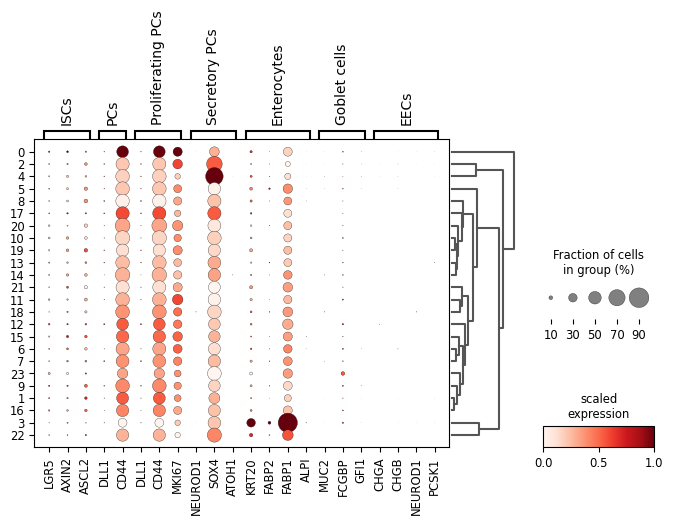

In [29]:
sc.pl.dotplot(
    adata,
    filtered_markers,              # dict[group] = list of genes
    groupby=cluster_key,
    dendrogram=True,               # uses the sc.tl.dendrogram result
    standard_scale="var",          # scale per gene for comparability
    mean_only_expressed=True,      # makes size reflect % expressing, color = mean
    swap_axes=False,               # clusters on x-axis (set True to flip)
    show=False,
    colorbar_title="scaled\nexpression",
    figsize=(8, 4)
)
# Save exactly like Scanpy expects (relative to sc.settings.figdir if set)
sc.pl.dotplot(
    adata,
    filtered_markers,
    groupby=cluster_key,
    dendrogram=True,
    standard_scale="var",
    mean_only_expressed=True,
    show=False,
    save="_markers_by_leiden_dotplot.pdf"   # yields e.g. 'figures/dotplot_markers_by_leiden_dotplot.pdf'
)



categories: 0, 1, 2, etc.
var_group_labels: ISCs, PCs, Proliferating PCs, etc.


/opt/anaconda3/envs/single-cell-env/lib/python3.11/site-packages/legacy_api_wrap/__init__.py:82: FutureWarning: `scale` is deprecated, use `density_norm` instead
  return fn(*args_all, **kw)


categories: 0, 1, 2, etc.
var_group_labels: ISCs, PCs, Proliferating PCs, etc.


/opt/anaconda3/envs/single-cell-env/lib/python3.11/site-packages/legacy_api_wrap/__init__.py:82: FutureWarning: `scale` is deprecated, use `density_norm` instead
  return fn(*args_all, **kw)


{'mainplot_ax': <Axes: >,
 'group_extra_ax': <Axes: >,
 'gene_group_ax': <Axes: >,
 'color_legend_ax': <Axes: title={'center': 'Median expression\nin group'}>}

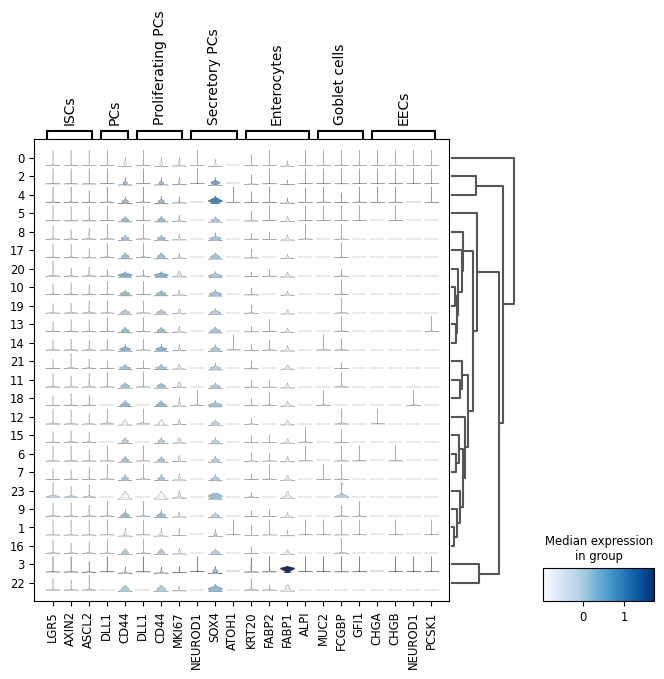

In [30]:
sc.pl.stacked_violin(
    adata,
    filtered_markers,
    groupby=cluster_key,
    dendrogram=True,
    scale="width",
    swap_axes=False,
    show=False,
    figsize=(8, 6)
)
sc.pl.stacked_violin(
    adata,
    filtered_markers,
    groupby=cluster_key,
    dendrogram=True,
    scale="width",
    swap_axes=False,
    show=False,
    save="_markers_by_leiden_violin.pdf"
)
